# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


# dictionary of all the objects for myself
`cells` = DF of 14970 rows (one row per cell photographed)

`STATE_ORDER` = list of 7 state names

`STATE_COLORS` = dict of 8 colors for plotting

`osi` = DF of ~4400 rows, osimertinib experiment only

`at_A`, `at_B` = DF of 3000 / ~1400 rows with name tag and state before and after treatment

`pairs` = df of 3000 rows with each cell's state before and after, side by side

`STATES` = list of 7 real states

`OUTCOMES` = list of 7 states plus `cleared`

`counts` = 7x8 DF of how many cells went from each state to each outcome

`P_hat` = 8x8 DF of above + cleared

`P_osi` = 8x8 numpy array, same as above with labels removed

`pi_mix` = numpy array,  starting mix of tumor

`traj` = numpy array, tumor's mix at each treatment cycle

`alive_df` = df of fraction alive per starting state per cycle


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


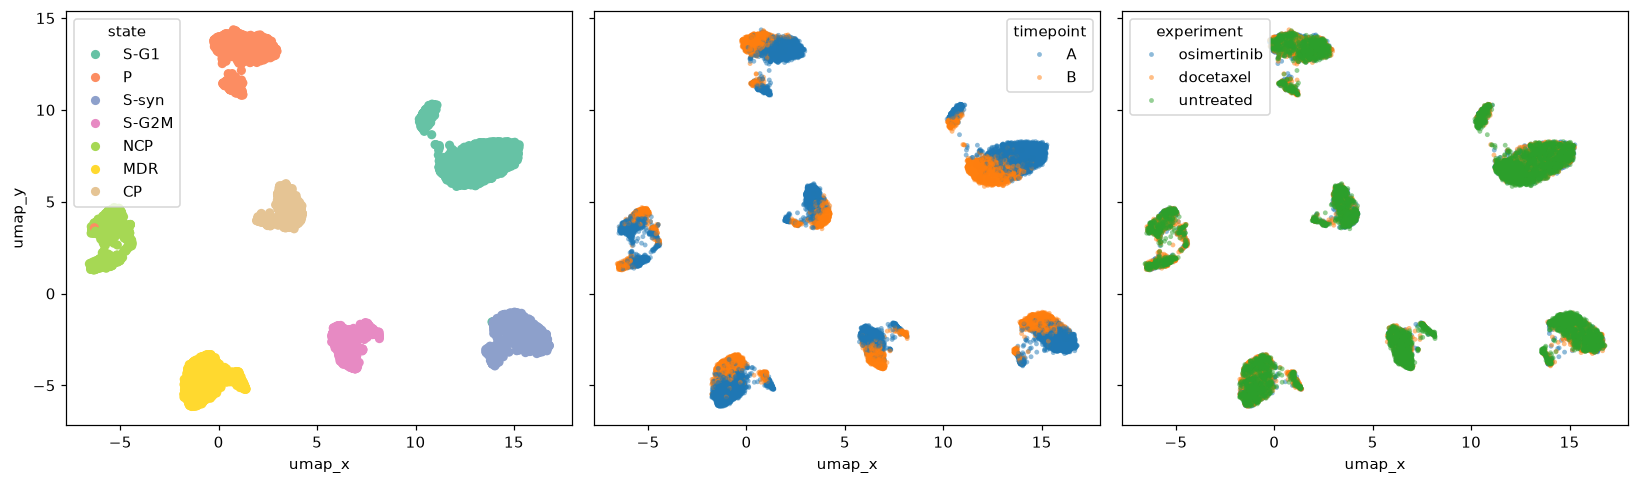

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

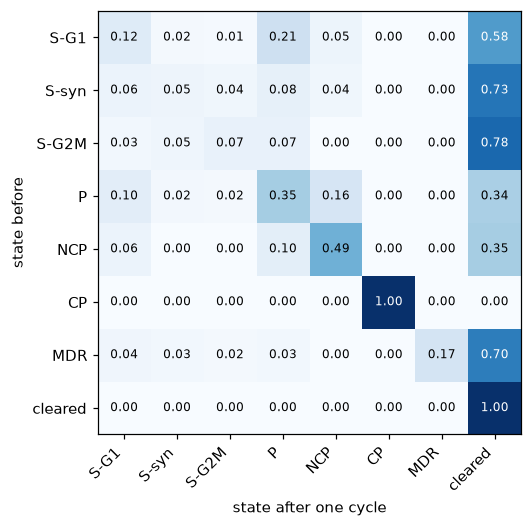

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

*Answer here.*

CP is approximately absorbing under osimertinib as it never leaves CP if it started there. This is in line with the state diagram, which says CP keeps subdividing under osimertinib. This means that osimertinib kills or moves everything else, and CP cells that were already in the tumor are what's left. This also shows that because that state (CP) never leaves and never dies, the tumor's floor is set by how much of it starts in that state.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

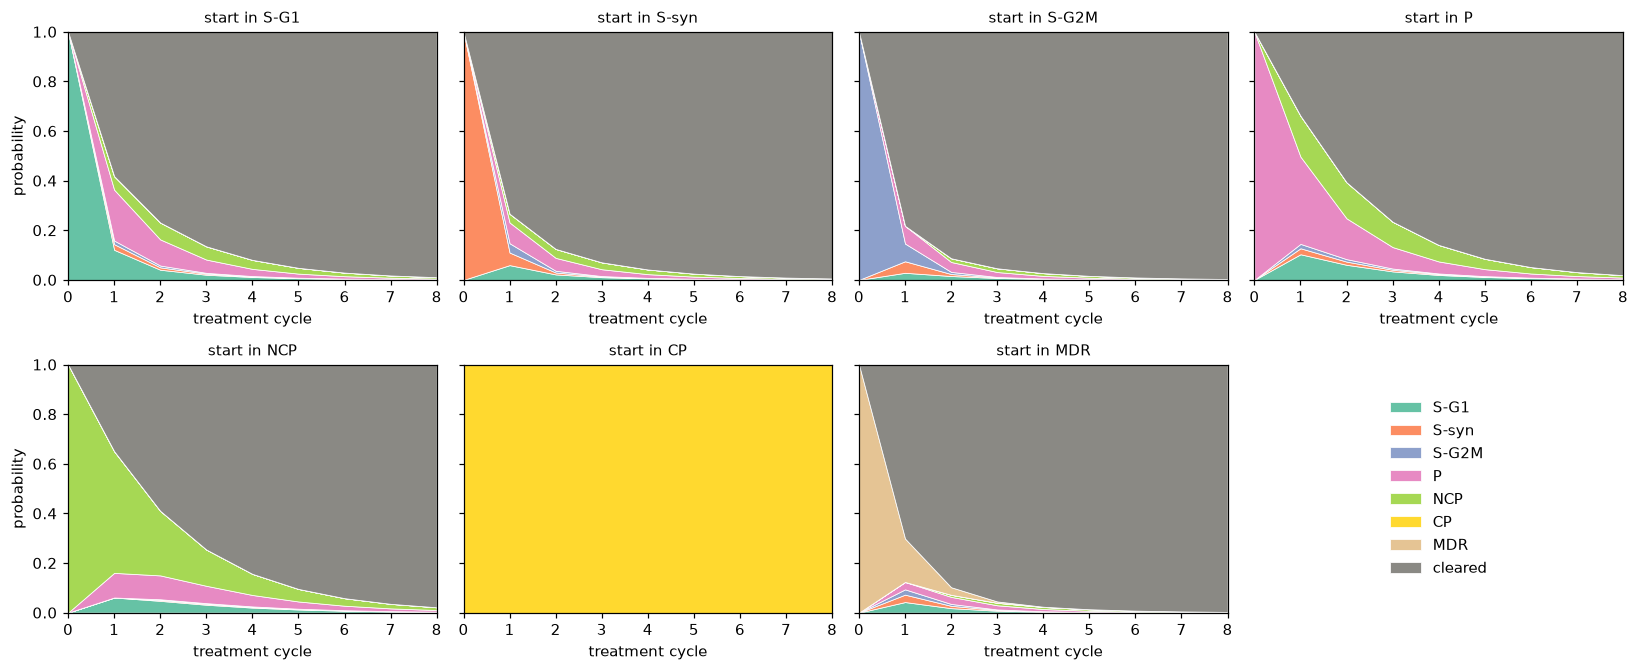

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?

Osmertinib eliminates every state except CP. Probability for the other 6 states decays towards cleared.


- Of the states that can be cleared, which tumor lasts the longest?

P and NCP last the longest.

- Which starting state sticks around for the most cycles of drug?

CP does, but NCP and P also stick around much longer than the others.

- Which starting state results in the highest proportion of alive cells after three cycles?

CP does - 100% of CP cells are alive after 3 cycles.
</div>


In [16]:
alive_table = {}
for s in STATES:
    traj = evolve(basis(s, P_hat), P_hat, 30)
    alive_table[s] = 1 - traj[:, -1]

alive_df = pd.DataFrame(alive_table).T

In [17]:
alive_df

,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
S-G1,1.0,0.418109,0.231063,0.135156,0.080605,0.048523,0.029353,0.017802,0.010811,0.006570,...,0.000017,0.000010,0.000006,0.000004,2.300508e-06,1.399142e-06,8.509423e-07,5.175333e-07,3.147578e-07,1.914321e-07
S-syn,1.0,0.266520,0.124826,0.070709,0.041949,0.025232,0.015261,0.009256,0.005621,0.003416,...,0.000009,0.000005,0.000003,0.000002,1.196051e-06,7.274245e-07,4.424112e-07,2.690694e-07,1.636449e-07,9.952697e-08
S-G2M,1.0,0.217857,0.087134,0.046717,0.027221,0.016254,0.009797,0.005931,0.003599,0.002186,...,0.000006,0.000003,0.000002,0.000001,7.649666e-07,4.652439e-07,2.829560e-07,1.720906e-07,1.046635e-07,6.365515e-08
P,1.0,0.661538,0.393341,0.234360,0.140828,0.085095,0.051576,0.031312,0.019026,0.011565,...,0.000030,0.000018,0.000011,0.000007,4.050812e-06,2.463657e-06,1.498368e-06,9.112901e-07,5.542362e-07,3.370801e-07
NCP,1.0,0.650641,0.410256,0.254336,0.156239,0.095518,0.058251,0.035477,0.021593,0.013137,...,0.000034,0.000020,0.000012,0.000008,4.605786e-06,2.801186e-06,1.703649e-06,1.036140e-06,6.301683e-07,3.832611e-07
CP,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
MDR,1.0,0.298507,0.102369,0.045077,0.023748,0.013626,0.008091,0.004870,0.002948,0.001789,...,0.000005,0.000003,0.000002,0.000001,6.254460e-07,3.803891e-07,2.313483e-07,1.407034e-07,8.557416e-08,5.204522e-08


### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

In [18]:
# Your code here
at_A_all = cells[cells["timepoint"] == "A"][["lineage_tag", "state"]]
pi_mix = at_A_all['state'].value_counts(normalize=True).reindex(OUTCOMES, fill_value=0).to_numpy() # set this equal to the starting vector from timepoint A

# evolve pi_mix and plot the results

In [19]:
pi_mix

array([0.247     , 0.14833333, 0.09944444, 0.15255556, 0.10244444,
       0.09722222, 0.153     , 0.        ])

In [20]:
alive_table_mix = {}
for s in STATES:
    traj = evolve(basis(s, P_hat), P_hat, 30)
    alive_table_mix[s] = 1 - traj[:, -1]

alive_mix_df = pd.DataFrame(alive_table_mix).T

In [21]:
alive_mix_df

,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
S-G1,1.0,0.418109,0.231063,0.135156,0.080605,0.048523,0.029353,0.017802,0.010811,0.006570,...,0.000017,0.000010,0.000006,0.000004,2.300508e-06,1.399142e-06,8.509423e-07,5.175333e-07,3.147578e-07,1.914321e-07
S-syn,1.0,0.266520,0.124826,0.070709,0.041949,0.025232,0.015261,0.009256,0.005621,0.003416,...,0.000009,0.000005,0.000003,0.000002,1.196051e-06,7.274245e-07,4.424112e-07,2.690694e-07,1.636449e-07,9.952697e-08
S-G2M,1.0,0.217857,0.087134,0.046717,0.027221,0.016254,0.009797,0.005931,0.003599,0.002186,...,0.000006,0.000003,0.000002,0.000001,7.649666e-07,4.652439e-07,2.829560e-07,1.720906e-07,1.046635e-07,6.365515e-08
P,1.0,0.661538,0.393341,0.234360,0.140828,0.085095,0.051576,0.031312,0.019026,0.011565,...,0.000030,0.000018,0.000011,0.000007,4.050812e-06,2.463657e-06,1.498368e-06,9.112901e-07,5.542362e-07,3.370801e-07
NCP,1.0,0.650641,0.410256,0.254336,0.156239,0.095518,0.058251,0.035477,0.021593,0.013137,...,0.000034,0.000020,0.000012,0.000008,4.605786e-06,2.801186e-06,1.703649e-06,1.036140e-06,6.301683e-07,3.832611e-07
CP,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
MDR,1.0,0.298507,0.102369,0.045077,0.023748,0.013626,0.008091,0.004870,0.002948,0.001789,...,0.000005,0.000003,0.000002,0.000001,6.254460e-07,3.803891e-07,2.313483e-07,1.407034e-07,8.557416e-08,5.204522e-08


In [22]:
traj_mix = evolve(pi_mix, P_hat, 30)

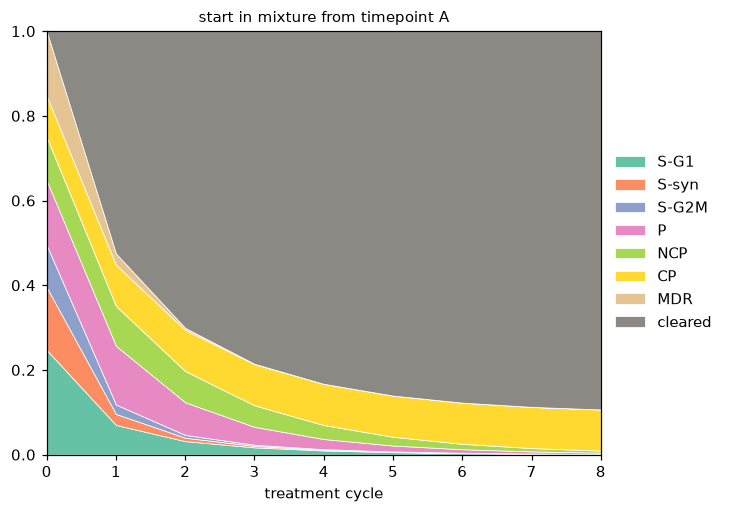

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 5))
plot_trajectory(evolve(pi_mix, P_hat, N_CYCLES), ax, "start in mixture from timepoint A")
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

*Answer Here*

CP ends up dominating the remaining cluster, and these cells will never be cleared using osimertinib. The long-run endpoint is determined by the absorbing states of P (cleared and CP). Every other state will either transition to cleared or pass into a state that does end in cleared. 

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [24]:
# doc transition matrix
doc = cells[cells["experiment"] == "docetaxel"]
at_A_doc = doc[doc.timepoint == "A"][["lineage_tag", "state"]]
at_B_doc = doc[doc.timepoint == "B"][["lineage_tag", "state"]]

doc_pairs = pd.merge(at_A_doc, at_B_doc, on="lineage_tag", how="left", suffixes=("_A", "_B"))
doc_pairs["state_B"] = doc_pairs["state_B"].fillna("cleared")

doc_pairs.head()

,lineage_tag,state_A,state_B
0,tagd-02372,S-G2M,cleared
1,tagd-02101,MDR,MDR
2,tagd-00385,P,P
3,tagd-01900,NCP,NCP
4,tagd-01795,P,S-G1


In [25]:
doc_counts = (pd.crosstab(doc_pairs.state_A, doc_pairs.state_B)
              .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_doc = doc_counts.div(doc_counts.sum(axis=1), axis=0)

In [26]:
print("transition counts:")
display(doc_counts)
print("estimated transition matrix (docetaxel, one cycle):")
P_doc.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,216,75,15,67,60,0,26,277
S-syn,22,49,60,22,14,0,0,273
S-G2M,8,7,10,6,6,0,0,247
P,43,19,10,195,35,0,7,168
NCP,24,0,1,30,139,0,7,118
CP,23,10,10,8,0,29,0,210
MDR,0,0,0,0,0,0,454,0


estimated transition matrix (docetaxel, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.293,0.102,0.020,0.091,0.082,0.0,0.035,0.376
S-syn,0.050,0.111,0.136,0.050,0.032,0.0,0.000,0.620
S-G2M,0.028,0.025,0.035,0.021,0.021,0.0,0.000,0.870
P,0.090,0.040,0.021,0.409,0.073,0.0,0.015,0.352
NCP,0.075,0.000,0.003,0.094,0.436,0.0,0.022,0.370
CP,0.079,0.034,0.034,0.028,0.000,0.1,0.000,0.724
MDR,0.000,0.000,0.000,0.000,0.000,0.0,1.000,0.000


In [27]:
P_doc.loc['cleared'] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_doc.columns})


In [28]:
# holiday transition matrix
holiday = cells[cells["experiment"] == "untreated"]
at_A_holiday = holiday[holiday.timepoint == "A"][["lineage_tag", "state"]]
at_B_holiday = holiday[holiday.timepoint == "B"][["lineage_tag", "state"]]
holiday_pairs = pd.merge(at_A_holiday, at_B_holiday, on="lineage_tag", how="left", suffixes=("_A", "_B"))
holiday_pairs["state_B"] = holiday_pairs["state_B"].fillna("cleared")

holiday_pairs.head()

,lineage_tag,state_A,state_B
0,tagd-01156,MDR,MDR
1,tagd-00441,S-G2M,S-syn
2,tagd-02679,P,S-G2M
3,tagd-02105,P,S-G1
4,tagd-02388,S-G2M,S-G2M


In [29]:
holiday_counts = (pd.crosstab(holiday_pairs.state_A, holiday_pairs.state_B)
                  .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_holiday = holiday_counts.div(holiday_counts.sum(axis=1), axis=0)

In [30]:
print("transition counts:")
display(holiday_counts)
print("estimated transition matrix (holiday, one cycle):")
P_holiday.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,303,317,79,0,0,0,0,37
S-syn,41,151,228,0,0,0,0,21
S-G2M,189,33,89,0,0,0,0,20
P,182,44,24,143,20,0,1,27
NCP,54,20,0,66,139,0,0,12
CP,18,10,11,0,0,251,0,16
MDR,145,20,20,0,0,0,246,23


estimated transition matrix (holiday, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.412,0.431,0.107,0.000,0.000,0.00,0.000,0.050
S-syn,0.093,0.342,0.517,0.000,0.000,0.00,0.000,0.048
S-G2M,0.571,0.100,0.269,0.000,0.000,0.00,0.000,0.060
P,0.413,0.100,0.054,0.324,0.045,0.00,0.002,0.061
NCP,0.186,0.069,0.000,0.227,0.478,0.00,0.000,0.041
CP,0.059,0.033,0.036,0.000,0.000,0.82,0.000,0.052
MDR,0.319,0.044,0.044,0.000,0.000,0.00,0.542,0.051


In [31]:
P_holiday.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_holiday.columns})

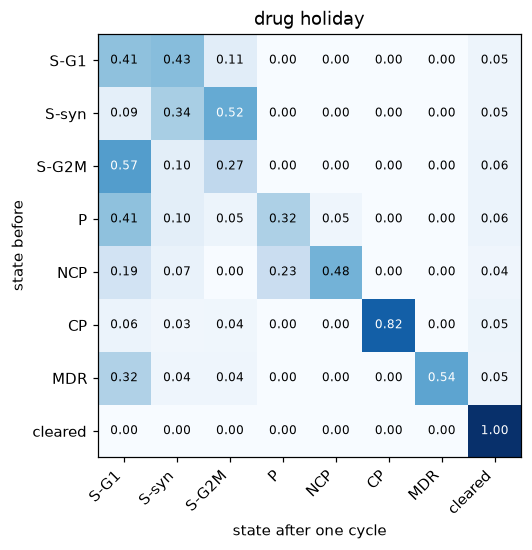

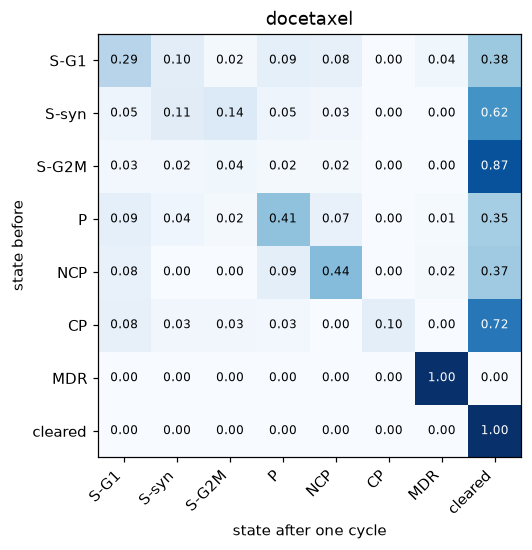

In [32]:
#Plot the transition matrices for docetaxel and the drug holiday.
show_matrix(P_holiday, title="drug holiday")
show_matrix(P_doc, title="docetaxel")

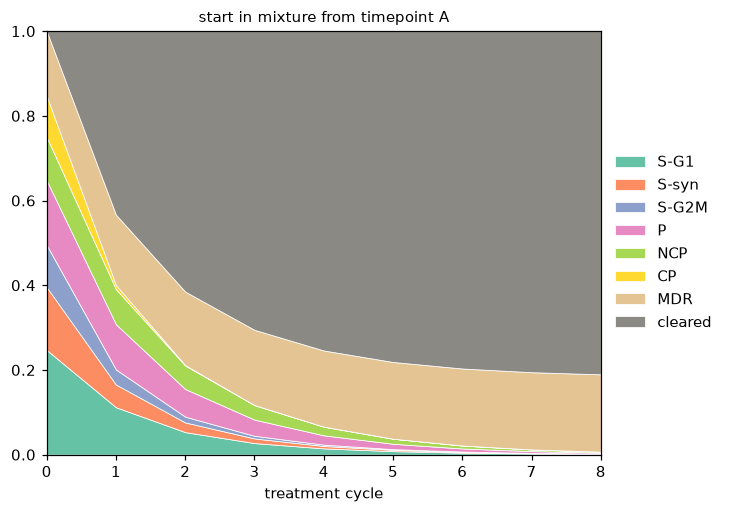

In [33]:
# Simulate the evolution of pi_mix under docetaxel 
fig, ax = plt.subplots(figsize=(6.5, 5))
plot_trajectory(evolve(pi_mix, P_doc, N_CYCLES), ax, "start in mixture from timepoint A")
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)

*Answer questions in markdown here.*

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?

Under a drug holiday, the transition matrix shows no fully absorbing states (other than cleared), though CP remains the stickiest state (p = 0.82). There are far more states that fewer cells leave compared to either of the treatments though - the majority of drug holiday's diagonas are upwards of .3.

Under the holiday, cells still leave their state but they leave by cycling (S-G1 -> S-syn -> S-G2M -> S-G1), not by dying. 

Under docetaxel, MDR is an absorbing state along with cleared though CP (the most resistant state that osimertinib fails to get rid of) loses that designation. 

2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

Almost all states transition to cleared by cycle 5, while MDR persists into round 8.


In [34]:
P_osi = P_hat.to_numpy()
P_doc = P_doc.to_numpy()
P_holiday = P_holiday.to_numpy()

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [35]:
## Add code here
def run_schedule(pi0, schedule):
    """schedule: list of 8x8 arrays, one per cycle
    Returns array of shape (len(schedule)+1, 8); row t = state after t cycles"""
    traj = [np.asarray(pi0, dtype=float)]
    for P in schedule:
        traj.append(traj[-1] @ P)
    return np.array(traj)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared,alive
osimertinib x 8,0.0013,0.0002,0.0001,0.0030,0.0048,0.0972,0.0000,0.8934,0.1066
docetaxel x 8,0.0015,0.0006,0.0003,0.0024,0.0023,0.0000,0.1826,0.8104,0.1896
alternating (osi first),0.0016,0.0005,0.0003,0.0030,0.0033,0.0000,0.0007,0.9906,0.0094
alternating (doc first),0.0014,0.0003,0.0002,0.0031,0.0038,0.0000,0.0003,0.9908,0.0092


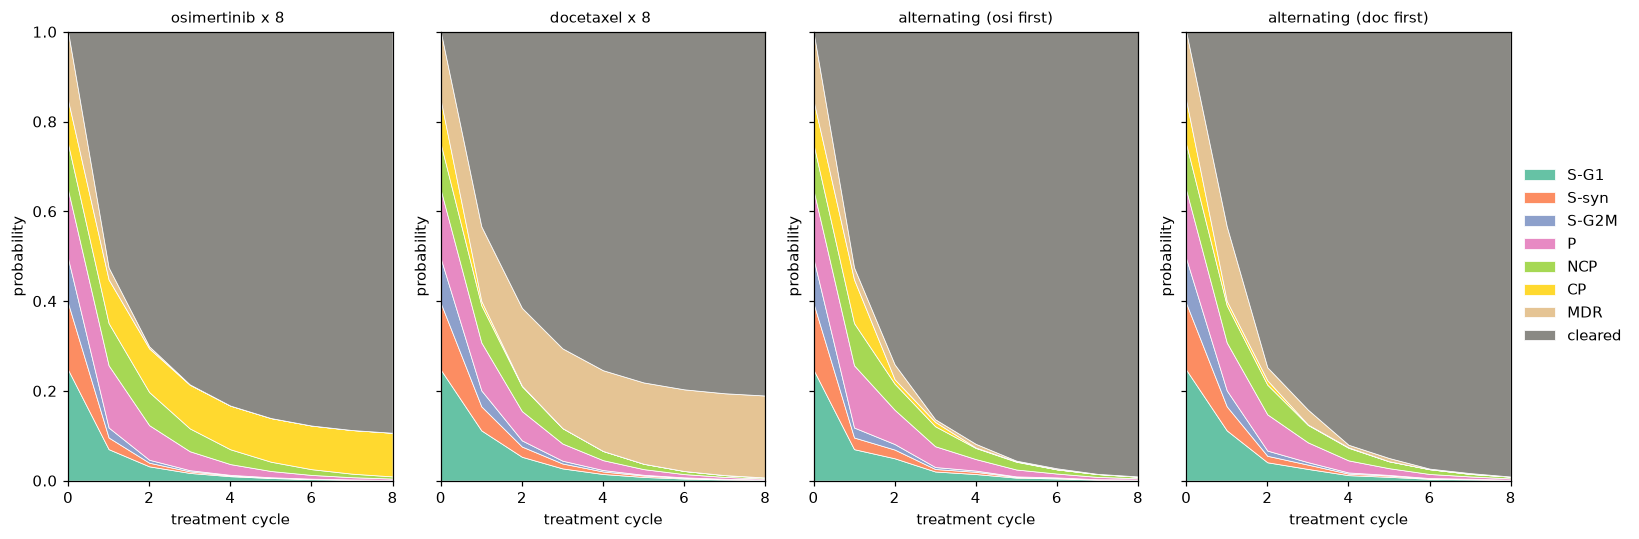

In [36]:
N_CYCLES = 8

# each schedule is list of matrices applied left to right
schedules = {
    "osimertinib x 8 ": [P_osi] * 8,
    "docetaxel x 8 ": [P_doc] * 8,
    "alternating (osi first)": [P_osi, P_doc] * 4,
    "alternating (doc first)": [P_doc, P_osi] * 4
}

# run every schedule starting from same tumor
trajs = {name: run_schedule(pi_mix, schedule) for name, schedule in schedules.items()} 

# summary table: what's left after 8 cycles and which states survivors are in
# traj[-1] is the last row of the trajectory, i.e. after 8 cycles. find final distribution by schedule name
# index=OUTCOMES to label rows with the state names
summary = pd.DataFrame({name: traj[-1] for name, traj in trajs.items()}, index=OUTCOMES).T
summary['alive'] = 1 - summary['cleared']
display(summary.round(4))


# side by side stacked area plots
fig, axes = plt.subplots(1, len(trajs), figsize=(15, 5), sharey=True)

for ax, (name, traj) in zip(axes, trajs.items()):
    plot_trajectory(traj, ax, name)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("treatment cycle")
    ax.set_ylabel("probability")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()


In [37]:
# checking stuff with drug holidays

starts = {
    "all MDR": basis("MDR", P_hat),
    "all CP": basis("CP", P_hat),
    "all S-G1": basis("S-G1", P_hat), # control with no resistant cells
}

holiday_schedules = {
    "doc x8": [P_doc] * 8,
    "1 holiday + doc x7": [P_holiday] + [P_doc] * 7,
    "2 holiday + doc x6": [P_holiday] * 2 + [P_doc] * 6,
    "osi x8": [P_osi] * 8,
    "1 holiday + osi x7": [P_holiday] + [P_osi] * 7,
    "2 holiday + osi x6": [P_holiday] * 2 + [P_osi] * 6,
}

# fraction still alive after 8 cycles for every (starting tumor + schedule) pair
# claude assisted dictionary comprehension 
q3 = pd.DataFrame({
    sched_name: {start_name: 1 - run_schedule(pi0, sched)[-1,-1]
                 for start_name, pi0 in starts.items()}
    for sched_name, sched in holiday_schedules.items()
})

q3

,doc x8,1 holiday + doc x7,2 holiday + doc x6,osi x8,1 holiday + osi x7,2 holiday + osi x6
all MDR,1.000000,0.568344,0.329022,0.002948,0.008994,0.015843
all CP,0.010086,0.015428,0.021479,1.000000,0.821824,0.677280
all S-G1,0.072661,0.040209,0.034637,0.010811,0.011952,0.015967


In [38]:
# dont think i need this anymore whatever
def alive_by_start(schedules, starts):
    alive_df = pd.DataFrame({
        sched_name: {start_name: 1 - run_schedule(pi0, sched)[-1, -1]
        for start_name, pi0 in starts.items()}
        for sched_name, sched in schedules.items()
    })

    return alive_df

In [39]:
# going to run a loop using above function with different schedules and output to table
# deciding that cured = fewer than 1 surviving cell
N_ROUNDS = 8
MAX_ROUNDS = 30
TUMOR_SIZE = 1000 # just assuming idk
THRESHOLD = 1 / TUMOR_SIZE

In [40]:
# starting tumors
start_tumors = {
    "all S-G1": basis("S-G1", P_hat),
    "all CP": basis("CP", P_hat),
    "all MDR": basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "98% S-G1, 2% MDR": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("MDR", P_hat),
    "measured mix": pi_mix
}

# schedules
schedule_rules = {
    "osi only": [P_osi] * MAX_ROUNDS,
    "doc only": [P_doc] * MAX_ROUNDS,
    "alt, osi first": [P_osi, P_doc] * (MAX_ROUNDS // 2),
    "alt, doc first": [P_doc, P_osi] * (MAX_ROUNDS // 2),
    "holiday + doc": [P_holiday] + [P_doc] * (MAX_ROUNDS-1)

}



In [41]:
def rounds_to_cure(alive):
    below = alive < THRESHOLD
    if not below.any(): # never reaches below threshold
        return np.nan
    return int(np.argmax(below)) # return first round below threshold


In [42]:
rows = []
for tumor, pi0 in start_tumors.items():
    for sched_name, rule in schedule_rules.items():
        traj = run_schedule(pi0, rule)
        alive = 1 - traj[:, -1]
        rows.append({   
            "tumor": tumor,
            "schedule":sched_name,
            "alive_8": alive[8],
            "rounds": rounds_to_cure(alive)
        })

multiple_treatments = pd.DataFrame(rows)
multiple_treatments

,tumor,schedule,alive_8,rounds
0,all S-G1,osi only,0.010811,13.0
1,all S-G1,doc only,0.072661,NaN
2,all S-G1,"alt, osi first",0.009922,13.0
3,all S-G1,"alt, doc first",0.010855,13.0
4,all S-G1,holiday + doc,0.040209,NaN
5,all CP,osi only,1.000000,NaN
6,all CP,doc only,0.010086,NaN
7,all CP,"alt, osi first",0.006392,12.0
8,all CP,"alt, doc first",0.003575,11.0
9,all CP,holiday + doc,0.015428,NaN


Osimertinib alone works as long as there is no CP. All S-G1, all MDR, 98% S-G1 and 2% MDR were all cured within 11-13 rounds. However, anything with CP is enough to prevent osimertinib from fully curing the tumor.

Alternating cures everything within 11-13 rounds, and it is the only schedule with no failures to cure (NaN).

Starting order only appears to matter for pure resistant tumors - all CP and all MDR have to be treated with the drug that kills them first to cure.

Docetaxel alone never cures anything, even pure CP, as every doc only and holiday + doc row is NaN.

*Answer questions here.*

After 8 cycles, osimertinib leaves 10.67% alive, almost all CP; docetaxel alone leaves 19.00% alive, almost all MDR. Each single drug fails because it has an absorbing resistant state (CP under osimertinib and MDR under docetaxel). Alternating works because each resistant drug is hit by the other drug every second cycle.

Osi-first leaves 0.0094 alive and doc-first leaves 0.0092%, a difference of 0.0002%. In principle order may matter because matrix multiplication isn't commutative, but for this tumor the effect difference seems minimal. 

A holiday appears to help if we're limited to the drug that the tumor resists (like if a patient is maybe allergic to the other drug). The holidays let resistant cells revert so the drug can work. MDR + doc goes to 0.33 with 2 holidays. This is because during a holiday, the resistant cells are able to transition to other states that the drug can then kill. For example, the transition matrix showed MDR -> S-G1 is 0.32 per cycle.
It doesn't help when the drug already kills the tumor; it just wastes a cycle.



## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [43]:
rng = np.random.default_rng(100)

In [44]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [45]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

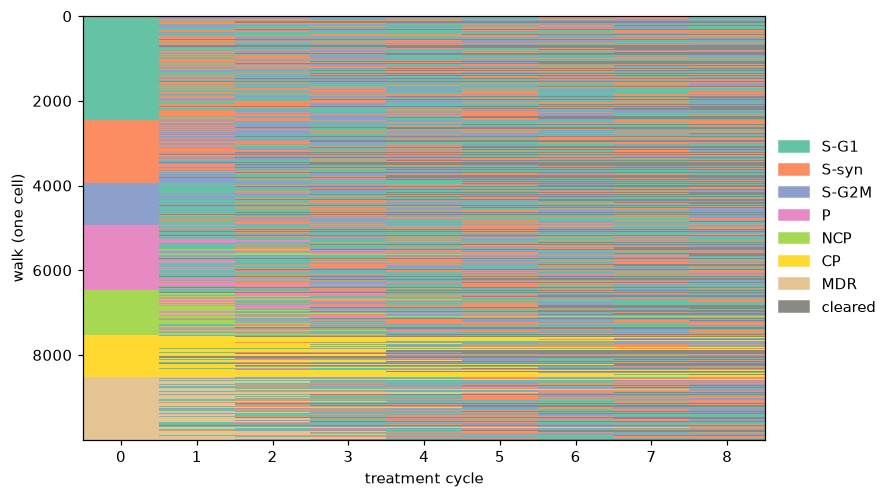

In [46]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting 
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [47]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

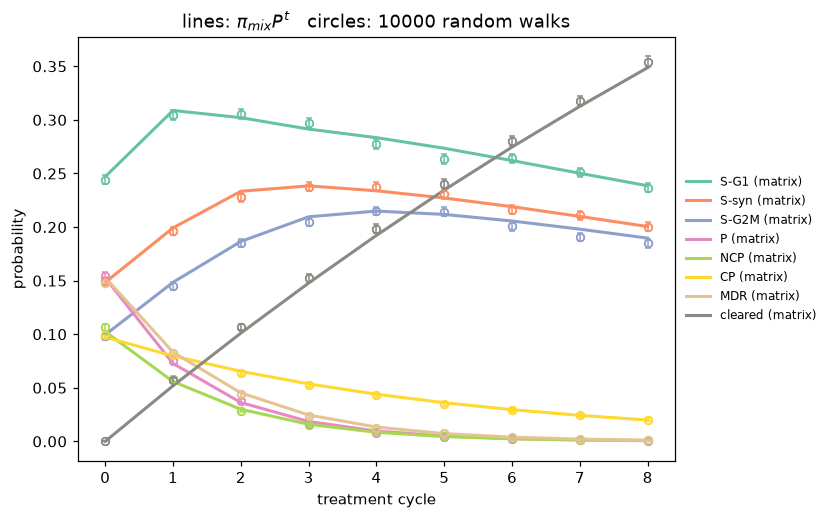

In [48]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

At 100 walks, circles scatter wildly around the lines, the error bars are large, and some circles miss the line by more than their error bar. Even at t = 0 the circles don't match because the starting states were random draws from pi_mix.

At 10_000 walks, the circles sit almost or on the lines and the error bars are tiny. The standard error comes from treating each cell as a yes/no trial (like is it in state j at time t) which makes the estimate a sample proportion with the square root of the sample size in the denominator. So, increasing the number of walks to 10_000 makes us 10x more precise than with 100 walks. Basically the law of large numbers says the sample proportion converges to the true probability as N gets bigger.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [49]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

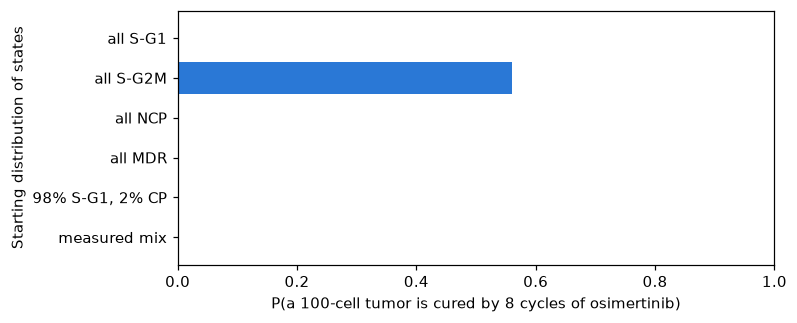

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.00,6.915,0.0
all S-G2M,0.56,0.575,0.0
all NCP,0.00,6.615,0.0
all MDR,0.00,100.000,0.0
"98% S-G1, 2% CP",0.00,6.950,0.0
measured mix,0.00,19.250,0.0


In [50]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

The results with docetaxel show that the only starting distribution it is capable of curing on its own within 8 rounds is a tumor amde of all S-G2M (P(cured) = 0.540) and an incredibly slim chance that it can cure a 98% S-G1, 2% CP distribution (P(cured) = 0.005).

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [ ]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test
PERSISTERS = {OUTCOMES.index("P"), OUTCOMES.index("NCP")}
def walk_with_flag(start, schedule, rng):
    run = 0
    flag = False
    path = [start]
    for P_t in schedule:
        new = step(path[-1], P_t, rng)
        path.append(new)
        if new in PERSISTERS:
            run = run + 1
        else:
            run = 0
        if run >= 3:
            flag = True
    return path, flag

def simulate_tumor_flags(pi0, P, n_cells, n_cycles, rng):
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    flags = []
    for s0 in starts:
        path, flag = walk_with_flag(s0, P, n_cycles, rng)
        flags.append(flag)
    return np.mean(flags)




In [90]:
fractions_osi = np.array([simulate_tumor_flags(pi_mix, [P_osi] * 8, 1000, 100, rng) for _ in range(100)])
fractions_osi

array([0.07 , 0.086, 0.083, 0.101, 0.069, 0.089, 0.093, 0.092, 0.077,
       0.083, 0.081, 0.077, 0.085, 0.093, 0.077, 0.071, 0.081, 0.087,
       0.08 , 0.077, 0.078, 0.083, 0.095, 0.081, 0.088, 0.09 , 0.08 ,
       0.085, 0.089, 0.073, 0.087, 0.087, 0.091, 0.071, 0.081, 0.08 ,
       0.078, 0.079, 0.079, 0.087, 0.084, 0.088, 0.091, 0.082, 0.076,
       0.073, 0.101, 0.089, 0.085, 0.07 , 0.098, 0.1  , 0.09 , 0.087,
       0.096, 0.083, 0.083, 0.091, 0.084, 0.095, 0.083, 0.089, 0.076,
       0.086, 0.088, 0.084, 0.062, 0.082, 0.066, 0.078, 0.067, 0.079,
       0.083, 0.073, 0.089, 0.081, 0.091, 0.089, 0.084, 0.078, 0.086,
       0.074, 0.089, 0.073, 0.072, 0.087, 0.078, 0.104, 0.083, 0.092,
       0.095, 0.079, 0.102, 0.076, 0.102, 0.087, 0.079, 0.071, 0.08 ,
       0.077])

In [91]:
mean = np.mean(fractions_osi)
sem = np.std(fractions_osi, ddof=1) / np.sqrt(len(fractions_osi))
print(f"Osimertinib (8 cycles): {mean:.2%} ± {sem:.2f} of cells permanently resistant.")
print(f"(mean ± SEM over {len(fractions_osi)} tumors of 1000 cells)")
lo, hi = mean - 1.96 * sem, mean + 1.96 * sem
print(f"95% CI: [{lo:.4f}, {hi:.4f}]")
pct_tumors_over = 100 * np.mean(fractions_osi > 0.10)
print(f"{pct_tumors_over}% of tumors with more than 10% permanently resistant cells.")

Osimertinib (8 cycles): 8.35% ± 0.00 of cells permanently resistant.
(mean ± SEM over 100 tumors of 1000 cells)
95% CI: [0.0819, 0.0852]
5.0% of tumors with more than 10% permanently resistant cells.


In [94]:
fractions_doc = np.array([simulate_tumor_flags(pi_mix, [P_doc] * 8, 1000, 100, rng) for _ in range(100)])
mean = np.mean(fractions_doc)
sem = np.std(fractions_doc, ddof=1) / np.sqrt(len(fractions_doc))
print(f"Docetaxol (8 cycles): {mean:.2%} ± {sem:.2f} of cells permanently resistant.")
print(f"(mean ± SEM over {len(fractions_osi)} tumors of 1000 cells)")
lo, hi = mean - 1.96 * sem, mean + 1.96 * sem
print(f"95% CI: [{lo:.4f}, {hi:.4f}]")
pct_tumors_over = 100 * np.mean(fractions_doc > 0.10)
print(f"{pct_tumors_over}% of tumors with more than 10% permanently resistant cells.")

Docetaxol (8 cycles): 5.94% ± 0.00 of cells permanently resistant.
(mean ± SEM over 100 tumors of 1000 cells)
95% CI: [0.0580, 0.0608]
0.0% of tumors with more than 10% permanently resistant cells.


In [97]:
fractions_alt = np.array([simulate_tumor_flags(pi_mix, [P_osi, P_doc] * 4, 1000, 100, rng) for _ in range(100)])
mean = np.mean(fractions_alt)
sem = np.std(fractions_alt, ddof=1) / np.sqrt(len(fractions_alt))
print(f"Alternating Osimertinib and Docetaxol: {mean:.2%} ± {sem:.2f} of cells permanently resistant.")
print(f"(mean ± SEM over {len(fractions_alt)} tumors of 1000 cells)")
lo, hi = mean - 1.96 * sem, mean + 1.96 * sem
print(f"95% CI: [{lo:.4f}, {hi:.4f}]")
pct_tumors_over = 100 * np.mean(fractions_alt > 0.10)
print(f"{pct_tumors_over}% of tumors with more than 10% permanently resistant cells.")

Alternating Osimertinib and Docetaxol: 7.53% ± 0.00 of cells permanently resistant.
(mean ± SEM over 100 tumors of 1000 cells)
95% CI: [0.0738, 0.0768]
0.0% of tumors with more than 10% permanently resistant cells.


In [98]:
doc_holiday_fractions = np.array([simulate_tumor_flags(pi_mix, [P_doc, P_holiday] * 4, 1000, 8, rng) for _ in range(100)])
mean = np.mean(doc_holiday_fractions)
sem = np.std(doc_holiday_fractions, ddof=1) / np.sqrt(len(doc_holiday_fractions))
print(f"Docetaxol with drug holiday: {mean:.2%} ± {sem:.2f} of cells permanently resistant.")
print(f"(mean ± SEM over {len(fractions_alt)} tumors of 1000 cells)")
lo, hi = mean - 1.96 * sem, mean + 1.96 * sem
print(f"95% CI: [{lo:.4f}, {hi:.4f}]")
pct_tumors_over = 100 * np.mean(doc_holiday_fractions > 0.10)
print(f"{pct_tumors_over}% of tumors with more than 10% permanently resistant cells.")

Docetaxol with drug holiday: 6.70% ± 0.00 of cells permanently resistant.
(mean ± SEM over 100 tumors of 1000 cells)
95% CI: [0.0654, 0.0685]
0.0% of tumors with more than 10% permanently resistant cells.


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

On average no treatment exceeded 10%, but under osimertinib 2-5% of individual tumors did; under alternating about 1% at 8 cycles, under docetaxel (with or without holidays), none. 

Increasing the number of cycles doesn't change the result. The fraction plateaus by about 8 cycles. The way I coded flags is permanent, so by then nearly every cellhas been cleared or is stuck in a resistant absorbing state (CP or MDR), so almost no cells remain in other states to start a new 3-cycle streak that would get it classified as resistant.

| Treatment        | Cycles | % Resistant | % of tumors with >10% permanently resistant |
|------------------|--------|-------------|---------------------------------------------|
| Osimertinib      | 8      | 8.26        | 5                                        |
| Osimertinib      | 20     | 8.12        | 2                                        |
| Osimertinib      | 100    | 8.24        | 5                                      |
| Docetaxol        | 8      | 5.95        | 0                                           |
| Docetaxol        | 20     | 6.07        | 0                                           |
| Docetaxol        | 100    | 5.83        | 0                                           |
| Alt. Osi + Doc   | 8      | 7.59        | 1                                           |
| Alt. Osi + Doc   | 20     | 7.53        | 0                                           |
| Alt. Osi + Doc   | 100    | 7.55        | 0                                           |
| Doc with Holiday | 8      | 6.53        | 0                                           |
| Doc with Holiday | 20     | 6.61        | 0                                           |
| Doc with Holiday | 100    | 6.59        | 0                                           |